In [ ]:
import pandas as pd
import numpy as np

df = pd.read_csv('./../data/raw/full_data.csv')

# Link to the dataset: https://www.kaggle.com/datasets/blastchar/telco-customer-churn/data

In [7]:
pd.set_option('display.max_columns', 400)

In [8]:
df.head()

,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,OnlineBackup,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,Yes,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,No,Yes,No,No,No,One year,No,Mailed check,56.95,1889.5,No
2,3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,Yes,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes
3,7795-CFOCW,Male,0,No,No,45,No,No phone service,DSL,Yes,No,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No
4,9237-HQITU,Female,0,No,No,2,Yes,No,Fiber optic,No,No,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes


In [26]:
from json import dumps, loads
from pprint import pprint
with open('./../data/raw/metadata.json') as f:
    pprint(loads(f.read()), sort_dicts=False)

{'customerID': 'Customer ID',
 'gender': 'male/female',
 'SeniorCitizen': 'senior or no',
 'Partner': 'has a partner',
 'Dependents': 'has dependents(childs, non working spouse)',
 'tenure': 'nbr of months the customer has stayed with the company',
 'PhoneService': 'has a phone service',
 'MultipleLines': 'has multiple line',
 'InternetService': "customer's internet service provider",
 'OnlineSecurity': 'if the customer has online security service',
 'OnlineBackup': 'if the customer has onlilne backup',
 'DeviceProtection': 'if the customer has device protection or not',
 'TechSupport': 'if the customer has tech suppport',
 'StreamingTV': 'if the customer has streaming tv',
 'StreamingMovies': 'if the customer has streaming movies or not',
 'Contract': 'the contract term of the customer(month-to-month, one,two years)',
 'PaperlessBilling': 'if the customer has paperless billing (invoice),like by '
                     'mail or e-mail',
 'PaymentMethod': "the customer's payment method",

In [9]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 7043 entries, 0 to 7042
Data columns (total 21 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   customerID        7043 non-null   object 
 1   gender            7043 non-null   object 
 2   SeniorCitizen     7043 non-null   int64  
 3   Partner           7043 non-null   object 
 4   Dependents        7043 non-null   object 
 5   tenure            7043 non-null   int64  
 6   PhoneService      7043 non-null   object 
 7   MultipleLines     7043 non-null   object 
 8   InternetService   7043 non-null   object 
 9   OnlineSecurity    7043 non-null   object 
 10  OnlineBackup      7043 non-null   object 
 11  DeviceProtection  7043 non-null   object 
 12  TechSupport       7043 non-null   object 
 13  StreamingTV       7043 non-null   object 
 14  StreamingMovies   7043 non-null   object 
 15  Contract          7043 non-null   object 
 16  PaperlessBilling  7043 non-null   object 


In [10]:
df.describe()

,SeniorCitizen,tenure,MonthlyCharges
count,7043.000000,7043.000000,7043.000000
mean,0.162147,32.371149,64.761692
std,0.368612,24.559481,30.090047
min,0.000000,0.000000,18.250000
25%,0.000000,9.000000,35.500000
50%,0.000000,29.000000,70.350000
75%,0.000000,55.000000,89.850000
max,1.000000,72.000000,118.750000


Churn
No     5174
Yes    1869
Name: count, dtype: int64

Churn
No     0.73
Yes    0.27
Name: count, dtype: float64


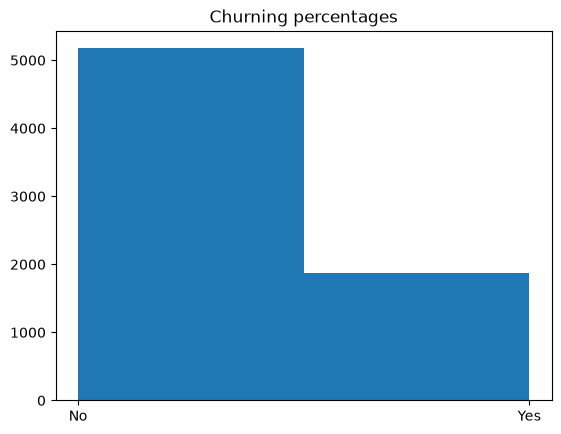

In [ ]:
import matplotlib.pyplot as plt
v = df.groupby('Churn')['Churn'].value_counts()
print(v)
print()
print(np.round(v/v.sum(), 2))


plt.hist(df['Churn'], bins=2)
plt.title('Churning percentages')
plt.show()

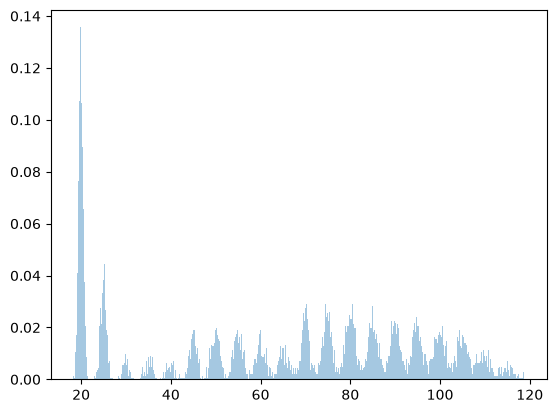

In [123]:
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt

s = pd.to_numeric(df['MonthlyCharges'], errors='coerce').dropna()

fig, ax = plt.subplots()
ax.hist(s, bins=500, density=True, alpha=0.4)
plt.show()